<a href="https://colab.research.google.com/github/nehadid/AAI2025/blob/2026fall/mod3ML/Kmeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset size: (200, 5)


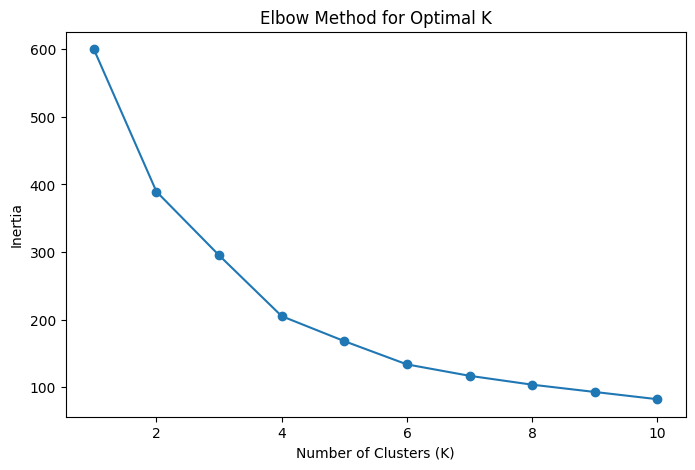

               Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                       
0        53.984615           47.707692               39.969231
1        32.875000           86.100000               81.525000
2        25.438596           40.000000               60.298246
3        39.368421           86.500000               19.578947


In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Data source: Mall Customers Dataset from GitHub
url = "https://raw.githubusercontent.com/aiplanethub/Datasets/master/Mall_Customers.csv"

df = pd.read_csv(url)

print("Dataset size:", df.shape)
df.head()

# Preprocess data: Select numerical features and scale them
features = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]

X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Elbow method
inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")
plt.show()

# Apply K-Means using 4 clusters
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)

# Analyze the clusters
cluster_summary = df.groupby("Cluster")[features].mean()
print(cluster_summary)

# Save results
df.to_csv("customer_segments.csv", index=False)